<a href="https://colab.research.google.com/github/Mamoun-AL-Sayaraa/Machine-Learning-Logistic_Regression/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Modify the linear regression script to work for logistic regression**

Linear Logistic Regression
Epoch 0, Loss: 0.6931
Epoch 1000, Loss: 0.4117
Epoch 2000, Loss: 0.4117
Epoch 3000, Loss: 0.4117
Epoch 4000, Loss: 0.4117

Quadratic Logistic Regression
Epoch 0, Loss: 0.6931
Epoch 1000, Loss: 0.1130
Epoch 2000, Loss: 0.0866
Epoch 3000, Loss: 0.0744
Epoch 4000, Loss: 0.0668

Linear Accuracy: 83.75%
Quadratic Accuracy: 98.75%


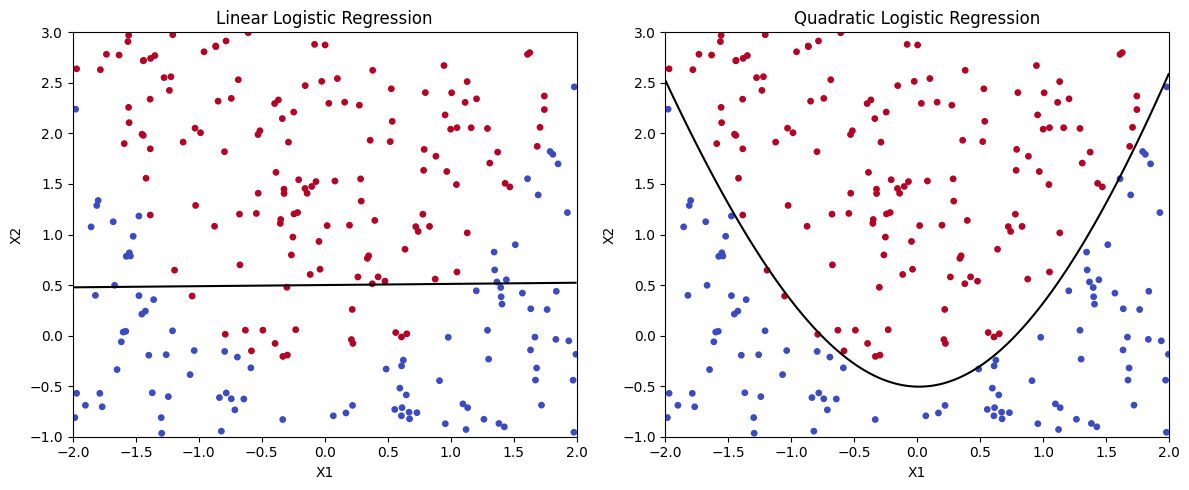

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def gradient_descent(X, y, learning_rate=0.1, epochs=5000):
    m, n = X.shape
    W = np.zeros(n + 1)

    # Original bias column
    X_b = np.c_[np.ones((m, 1)), X]

    for epoch in range(epochs):
        z = X_b.dot(W)

        # UPDATED: Apply the sigmoid function for logistic regression
        z = np.clip(z, -500, 500)
        y_pred = 1 / (1 + np.exp(-z))

        # UPDATED: Calculate the logistic regression gradient
        error = y_pred - y
        gradient = (1 / m) * X_b.T.dot(error)
        W -= learning_rate * gradient

        # UPDATED: Calculate binary cross-entropy loss
        if epoch % 1000 == 0:
            p = np.clip(y_pred, 1e-10, 1 - 1e-10)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            print(f"Epoch {epoch}, Loss: {loss:.4f}")

    return W


# UPDATED: Convert features to quadratic features
def quadratic_features(X):
    x1 = X[:, 0]
    x2 = X[:, 1]

    return np.column_stack([
        X,
        x1**2,
        x1 * x2,
        x2**2 ])


# UPDATED: Predict the class using logistic regression
def predict(X, W):
    X_b = np.c_[np.ones((len(X), 1)), X]
    z = np.clip(X_b.dot(W), -500, 500)
    probabilities = 1 / (1 + np.exp(-z))
    return (probabilities >= 0.5).astype(int)


if __name__ == "__main__":

    # UPDATED: Generate two classes separated by a parabola
    rng = np.random.default_rng(42)

    X = np.column_stack([
        rng.uniform(-2, 2, 1200),
        rng.uniform(-1, 3, 1200) ])

    y = (X[:, 1] > 0.8 * X[:, 0]**2 - 0.5).astype(int)

    # UPDATED: Split the data into training and testing sets
    indices = rng.permutation(len(X))
    split = int(0.8 * len(X))

    train = indices[:split]
    test = indices[split:]

    X_train, y_train = X[train], y[train]
    X_test, y_test = X[test], y[test]

    # Train linear logistic regression
    print("Linear Logistic Regression")
    W_linear = gradient_descent(X_train, y_train)

    # Train quadratic logistic regression
    print("\nQuadratic Logistic Regression")
    X_train_q = quadratic_features(X_train)
    X_test_q = quadratic_features(X_test)
    W_quad = gradient_descent(X_train_q, y_train)

    # Evaluate both models
    linear_accuracy = np.mean( predict(X_test, W_linear) == y_test ) * 100
    quadratic_accuracy = np.mean( predict(X_test_q, W_quad) == y_test ) * 100

    print(f"\nLinear Accuracy: {linear_accuracy:.2f}%")
    print(f"Quadratic Accuracy: {quadratic_accuracy:.2f}%")

    # UPDATED: Plot the decision boundaries
    xx, yy = np.meshgrid(np.linspace(-2, 2, 250),np.linspace(-1, 3, 250) )
    grid = np.column_stack([xx.ravel(), yy.ravel()])

    # Linear decision scores
    grid_linear = np.c_[np.ones(len(grid)), grid]
    scores_linear = grid_linear.dot(W_linear).reshape(xx.shape)

    # Quadratic decision scores
    grid_q = quadratic_features(grid)
    grid_q = np.c_[np.ones(len(grid_q)), grid_q]
    scores_quadratic = grid_q.dot(W_quad).reshape(xx.shape)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(X_test[:, 0], X_test[:, 1],c=y_test, cmap="coolwarm", s=15 )
    axes[0].contour(xx, yy, scores_linear, levels=[0], colors="black" )
    axes[0].set_title("Linear Logistic Regression")
    axes[0].set_xlabel("X1")
    axes[0].set_ylabel("X2")

    axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", s=15)
    axes[1].contour( xx, yy, scores_quadratic, levels=[0], colors="black")
    axes[1].set_title("Quadratic Logistic Regression")
    axes[1].set_xlabel("X1")
    axes[1].set_ylabel("X2")

    plt.tight_layout()
    plt.show()